In [3]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

conn = sqlite3.connect("../data/powerlifting.db")

q_dots = """
WITH por_persona AS (
    SELECT Name, Sex,
           MAX(CASE WHEN Equipment = 'Raw' THEN Dots END) AS mejor_raw,
           MAX(CASE WHEN Equipment = 'Single-ply' THEN Dots END) AS mejor_single
    FROM powerlifting
    WHERE Sex IN ('M', 'F') AND Year >= 2015
    GROUP BY Name, Sex
)
SELECT Sex,
       ROUND(AVG(mejor_raw), 1) AS Raw,
       ROUND(AVG(mejor_single), 1) AS "Single-ply"
FROM por_persona
WHERE mejor_raw IS NOT NULL AND mejor_single IS NOT NULL
GROUP BY Sex
"""

q_lifts = """
WITH por_persona AS (
    SELECT Name, Sex,
           MAX(CASE WHEN Equipment = 'Raw' THEN Best3SquatKg / BodyweightKg END) AS sq_raw,
           MAX(CASE WHEN Equipment = 'Single-ply' THEN Best3SquatKg / BodyweightKg END) AS sq_sp,
           MAX(CASE WHEN Equipment = 'Raw' THEN Best3BenchKg / BodyweightKg END) AS bn_raw,
           MAX(CASE WHEN Equipment = 'Single-ply' THEN Best3BenchKg / BodyweightKg END) AS bn_sp,
           MAX(CASE WHEN Equipment = 'Raw' THEN Best3DeadliftKg / BodyweightKg END) AS dl_raw,
           MAX(CASE WHEN Equipment = 'Single-ply' THEN Best3DeadliftKg / BodyweightKg END) AS dl_sp
    FROM powerlifting
    WHERE Sex IN ('M', 'F') AND Year >= 2015
      AND Best3SquatKg > 0 AND Best3BenchKg > 0 AND Best3DeadliftKg > 0
    GROUP BY Name, Sex
)
SELECT Sex,
       ROUND(AVG(sq_sp - sq_raw), 2) AS Sentadilla,
       ROUND(AVG(bn_sp - bn_raw), 2) AS Banca,
       ROUND(AVG(dl_sp - dl_raw), 2) AS "Peso muerto"
FROM por_persona
WHERE sq_raw IS NOT NULL AND sq_sp IS NOT NULL
  AND bn_raw IS NOT NULL AND bn_sp IS NOT NULL
  AND dl_raw IS NOT NULL AND dl_sp IS NOT NULL
GROUP BY Sex
"""

sexos = {"M": "Hombres", "F": "Mujeres"}
dots = pd.read_sql_query(q_dots, conn).set_index("Sex").rename(index=sexos).loc[["Hombres", "Mujeres"]]
lifts = pd.read_sql_query(q_lifts, conn).set_index("Sex").rename(index=sexos).loc[["Hombres", "Mujeres"]].T

In [4]:
display(dots)
display(lifts)

,Raw,Single-ply
Sex,,
Hombres,362.7,375.2
Mujeres,324.3,356.1


Sex,Hombres,Mujeres
Sentadilla,0.19,0.29
Banca,0.10,0.14
Peso muerto,-0.06,0.05


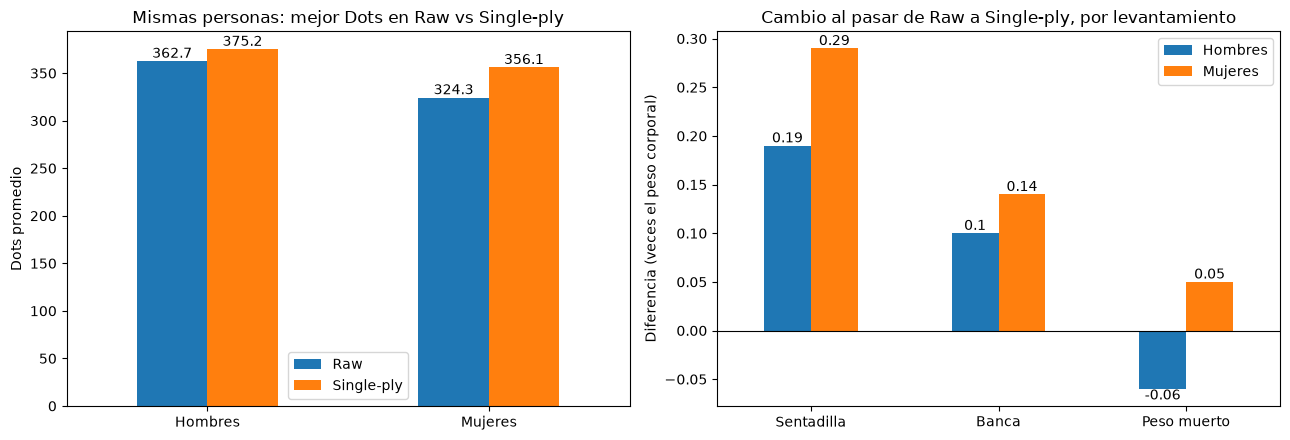

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

dots.plot(kind="bar", ax=ax[0], rot=0)
for c in ax[0].containers:
    ax[0].bar_label(c)
ax[0].set_title("Mismas personas: mejor Dots en Raw vs Single-ply")
ax[0].set_xlabel("")
ax[0].set_ylabel("Dots promedio")

lifts.plot(kind="bar", ax=ax[1], rot=0)
for c in ax[1].containers:
    ax[1].bar_label(c)
ax[1].axhline(0, color="black", linewidth=0.8)
ax[1].set_title("Cambio al pasar de Raw a Single-ply, por levantamiento")
ax[1].set_xlabel("")
ax[1].set_ylabel("Diferencia (veces el peso corporal)")
ax[1].legend(title="")

plt.tight_layout()
plt.savefig("../images/equipamiento.png", dpi=150)
plt.show()